# 09 The demo: the whole project in one notebook

**What this notebook is.** The whole project in about ten minutes. Sections 1
to 10 show every step of the project in one picture each, from the raw wafers to the final test table. Section 11
is the live part: pick any wafer, and the model says what's wrong with it.

**Why it's built this way.** Nothing here is calculated again. It only loads what notebooks 01 to 08 saved and
draws it. So it runs in about a minute, and every number on screen is the same number as in `output/`.

**How to read it.** Each section has "In short" for the point, a picture, and "What it shows" for the detail. Section 11 is live.

**In:** everything in `data/` and `output/` **Out:** nothing

## 0. Load everything

Everything the other notebooks saved. `read_csv` and `wafers_with_only` are two small helpers: the first reads a
.csv into rows, the second finds the wafers with exactly one defect.

In [1]:
import csv    # reading .csv files
import os     # checking whether a file exists
import time   # timing the live demo

import numpy as np
import matplotlib.pyplot as plt
import joblib                          # loads a trained model that 05 saved to a file
from sklearn.tree import export_text   # prints a decision tree as text

import wafer   # my own wafer.py: the defect names, the features, the scores

# Stop if the saved files come from different runs
# (it compares the files' dates: a file made later in the pipeline must not be older than one made before it)
wafer.check_one_run()

# np.load on an .npz gives a dictionary-like object: file["name"] is one saved array.
original = np.load("../data/Wafer_Map_Datasets.npz")   # the raw dataset: arr_0 = maps, arr_1 = labels
split = np.load("output/split.npz")                   # the cleaned maps, labels and which rows are train/val/test
# allow_pickle=True: this file also holds arrays of Python objects (like text). numpy refuses those by
# default, because loading them can run code. It's my own file, so it's safe here.
f = np.load("output/features.npz", allow_pickle=True)
answers = np.load("output/test_predictions.npz")   # what the forest and the baseline said on the test part
forest = joblib.load("output/forest.joblib")        # the trained random forest from 05
# The demo predicts one wafer at a time, so one core: starting workers costs more than one row
# (n_jobs = how many processor cores it uses; -1 would mean all of them)
forest.set_params(n_jobs=1)

maps = split["maps"]       # every cleaned wafer, shape (wafers, 52, 52)
labels = split["labels"]   # per wafer 8 zeros/ones, in the order of wafer.DEFECTS
# test_idx is a list of row numbers. maps[list] picks exactly those rows: only the test wafers.
test_maps = maps[split["test_idx"]]
test_labels = labels[split["test_idx"]]
y_test = answers["y_test"]   # the true labels of the test wafers
y_pred = answers["y_pred"]   # what the forest said
y_base = answers["y_base"]   # what the simple baseline model from 04 said


def read_csv(path):
    # DictReader gives every row as a dictionary: row["column name"] -> the value, always as text
    with open(path, encoding="utf-8") as file:
        return list(csv.DictReader(file))


def wafers_with_only(defect_name, which_labels):
    # Positions of the wafers with this one defect and nothing else
    # wanted is a label like [1 0 0 0 0 0 0 0]: a 1 only at this defect's position
    wanted = np.zeros(8, dtype=which_labels.dtype)
    wanted[wafer.DEFECTS.index(defect_name)] = 1
    # compare every row with wanted; .all(axis=1) is True only where all 8 match; np.where gives those rows
    return np.where((which_labels == wanted).all(axis=1))[0]


print("Loaded: the split, the features, the model and the test answers")

Loaded: the split, the features, the model and the test answers


## 1. The problem: what a wafer map is

**In short:** A wafer is a disc of silicon with many chips on it. After testing, every chip passed or failed. This map shows that: green is a good chip, yellow a failed one, dark purple is no chip. The failed chips make a pattern, and the pattern points an engineer at the cause, like a scratching tool or a bad edge. My model names the patterns. These are the 8 basic ones.

**How to read it:** One real wafer per pattern. Look at where the yellow sits.

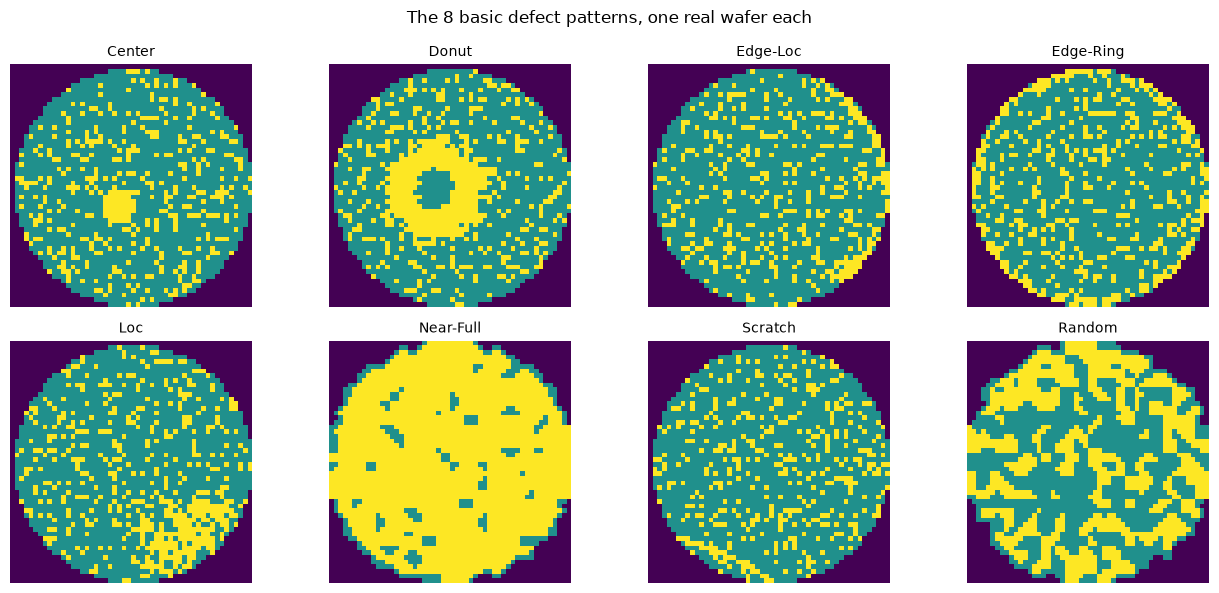

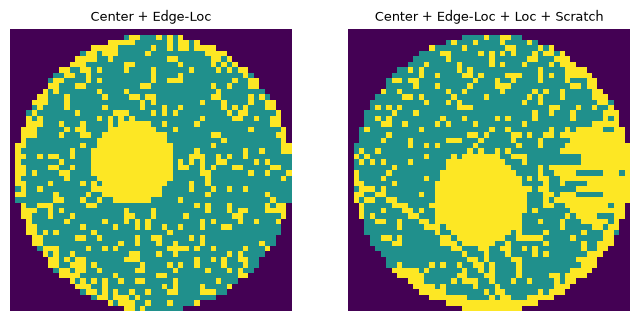

In [2]:
# figsize=(width, height) in inches for the whole picture
plt.figure(figsize=(13, 6))
for i in range(8):
    # a grid of 2 rows and 4 columns; places are counted from 1, so i + 1
    plt.subplot(2, 4, i + 1)
    # the first wafer that has only defect i; imshow draws the 52 x 52 numbers as colours
    plt.imshow(maps[wafers_with_only(wafer.DEFECTS[i], labels)[0]])
    plt.title(wafer.DEFECTS[i], fontsize=10)
    plt.axis("off")   # no tick numbers around the picture
plt.suptitle("The 8 basic defect patterns, one real wafer each")   # one title above all 8
plt.tight_layout()   # push the plots apart so titles don't overlap
plt.show()

# Most wafers have several patterns at once, that's the hard part
# sum(axis=1) adds up the 8 zeros/ones per wafer: how many defects it has
how_many = labels.sum(axis=1)
two = np.where(how_many == 2)[0][0]    # the first wafer with exactly 2 defects
four = np.where(how_many == 4)[0][0]   # the first wafer with exactly 4
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(maps[two])
plt.title(wafer.label_name(labels[two]), fontsize=9)   # label_name turns [1 0 1 ...] into "Center + Edge-Loc"
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(maps[four])
plt.title(wafer.label_name(labels[four]), fontsize=9)
plt.axis("off")
plt.show()

**What it shows:** Center in the middle, Donut as a ring around the middle, Edge-Loc as a spot on the edge, Edge-Ring all along the edge, Loc as a blob somewhere, Near-Full almost everything, Scratch as a line, Random everywhere. Then two wafers with two and four patterns on top of each other.

## 2. The data, and what the description didn't say

**In short:** MixedWM38 has about 38,000 maps in 38 types, by its description. When I checked the description against the file, two things weren't in it: maps that are in the file more than once, and wafers with a value 3 nobody explains. I took both out before splitting, otherwise a copy could be in training and in the test, and the score would look better than it is.

**How to read it:** The first chart is what cleaning took out. The second is how many wafers every type has after cleaning, smallest on the left.

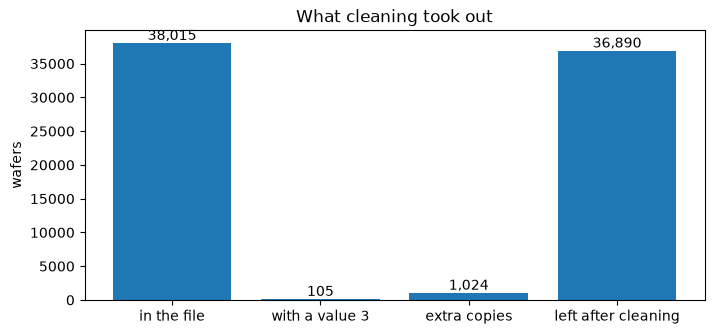

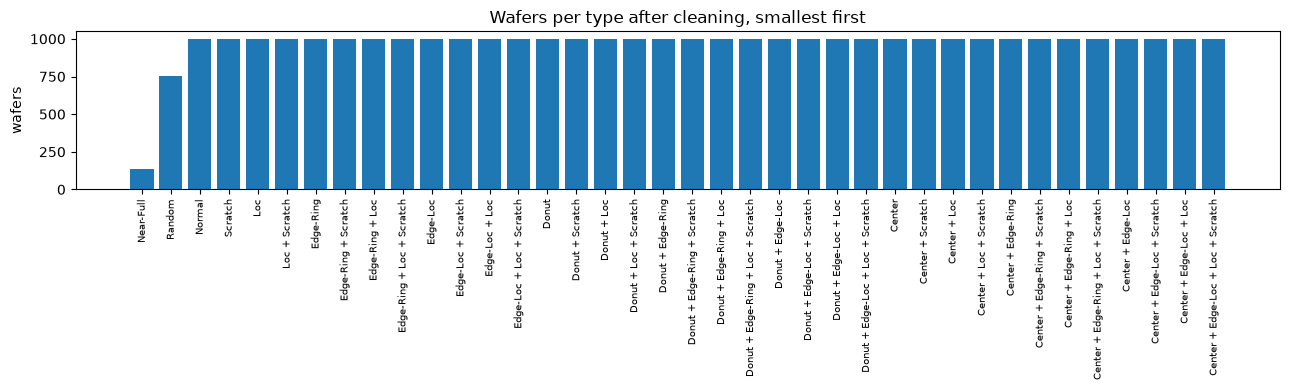

In [3]:
raw = original["arr_0"]   # the maps as they are in the downloaded file, before cleaning

# (raw == 3) is True on every square with a 3. .any(axis=(1, 2)) asks per wafer "is there a 3 anywhere
# in its rows and columns?", and .sum() counts the wafers where that's True.
with_3 = (raw == 3).any(axis=(1, 2)).sum()

# reshape(len(raw), -1) flattens every 52 x 52 map into one row of 2704 numbers (-1 = "work it out").
# np.unique(..., axis=0) keeps every different row once, so its length is the number of different maps.
different = len(np.unique(raw.reshape(len(raw), -1), axis=0))

steps = ["in the file", "with a value 3", "extra copies", "left after cleaning"]
counts = [len(raw), with_3, len(raw) - different, len(maps)]
plt.figure(figsize=(8, 3.5))
plt.bar(steps, counts)   # bar(names under the bars, heights)
for k in range(len(counts)):
    # the number on top of bar k. :, puts a comma every 3 digits (38,015).
    # ha="center": centred on the bar; va="bottom": the text's bottom sits on the bar's top
    plt.text(k, counts[k], f"{counts[k]:,}", ha="center", va="bottom")
plt.title("What cleaning took out")
plt.ylabel("wafers")
plt.show()

# Every different label (like [1 0 0 0 0 0 1 0]) is one type. return_counts=True also gives how often each one occurs.
combos, combo_counts = np.unique(labels, axis=0, return_counts=True)
# argsort gives the positions that would sort the counts from small to large
order = np.argsort(combo_counts)
names = []
for i in order:
    names.append(wafer.label_name(combos[i]))
plt.figure(figsize=(13, 4))
plt.bar(range(len(order)), combo_counts[order])   # bars at 0, 1, 2 ..., smallest type first
# xticks(positions, texts): the type names under the bars, turned 90 degrees so 38 of them fit
plt.xticks(range(len(order)), names, rotation=90, fontsize=7)
plt.title("Wafers per type after cleaning, smallest first")
plt.ylabel("wafers")
plt.tight_layout()
plt.show()

**What it shows:** What cleaning took out, step by step, and how many wafers every type has after cleaning. The small
types on the left are the reason I split per type: a random split could leave them out of the test.

## 3. The split: learn, practise, exam

**In short:** Every type is cut 70/15/15, with seed 42 so it's the same every run. The model learns from training, I choose its settings on validation, and the test part is the final exam, opened once. So the final score is on wafers the model has never seen.

**How to read it:** The size of each part.

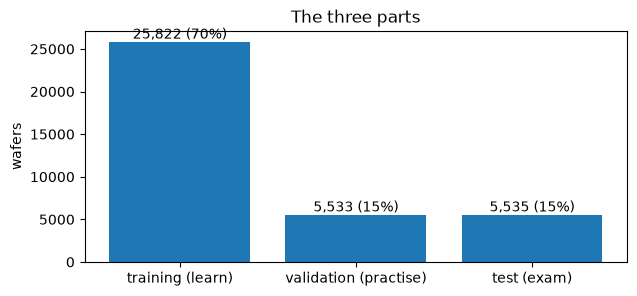

In [4]:
parts = ["training (learn)", "validation (practise)", "test (exam)"]
# train_idx etc. are lists of row numbers, so their length is the number of wafers in that part
sizes = [len(split["train_idx"]), len(split["val_idx"]), len(split["test_idx"])]
plt.figure(figsize=(7, 3))
plt.bar(parts, sizes)
for k in range(3):
    # the count with commas, and the share as a percentage with 0 decimals (:.0f)
    plt.text(k, sizes[k], f"{sizes[k]:,} ({sizes[k] / sum(sizes) * 100:.0f}%)", ha="center", va="bottom")
plt.title("The three parts")
plt.ylabel("wafers")
plt.show()

**What it shows:** The size of each part, close to 70/15/15.

## 4. Inside the features: from a picture to 14 numbers

**In short:** The model never sees the picture. It gets 14 numbers I measure from it: the share of failed chips on the whole wafer, in 5 rings from the middle out, and in 8 slices around the middle. That's how a picture becomes something a decision tree can ask questions about.

**How to read it:** The white lines show the rings and slices over a real Center wafer. Below that, the 14 numbers of four wafers: the blue bars are that wafer, the light bars an average Normal wafer.

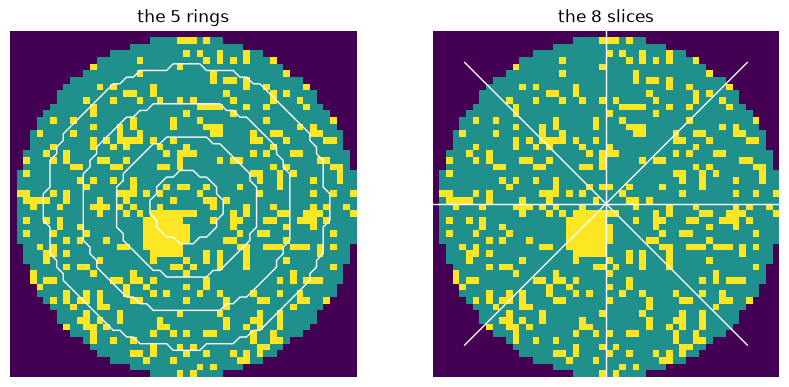

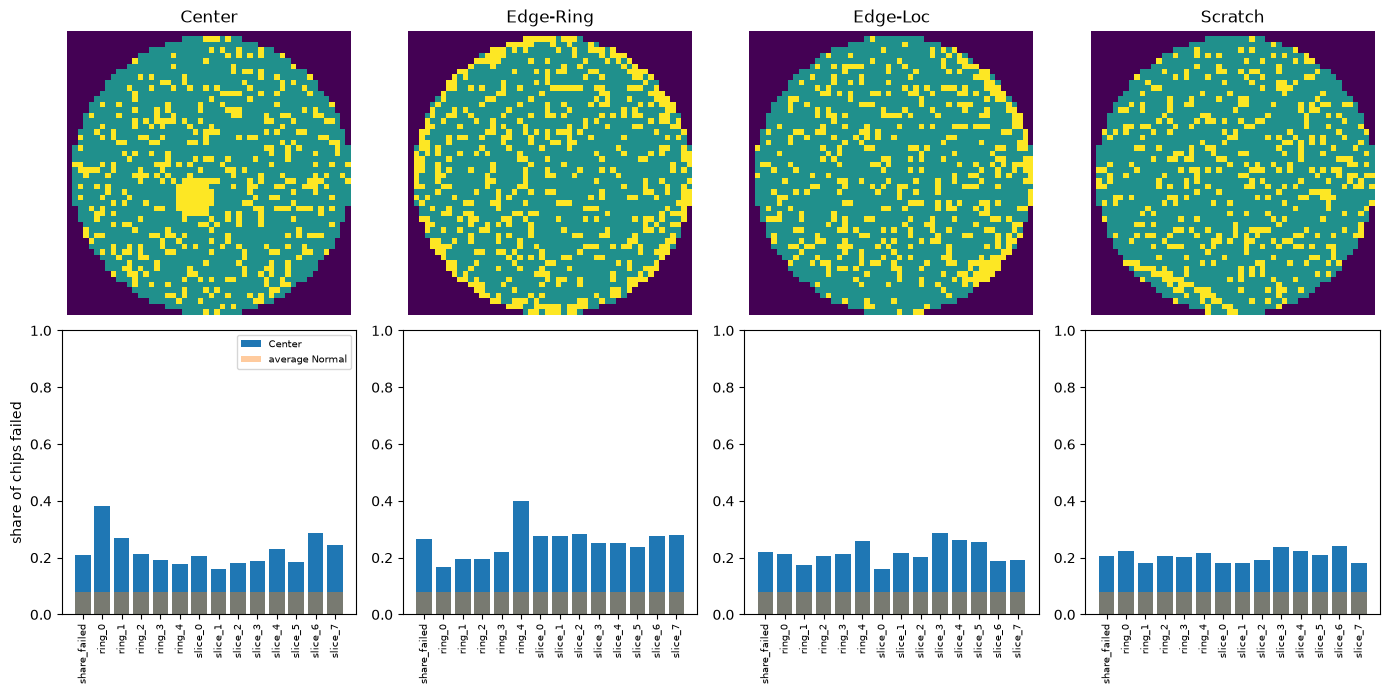

In [5]:
center = wafers_with_only("Center", labels)[0]   # one wafer with only a Center
plt.figure(figsize=(10, 4.5))

plt.subplot(1, 2, 1)
plt.imshow(maps[center])
# contour draws lines where a grid changes value. RING goes 0, 1, 2, 3, 4 from the middle out, so lines
# at 0.5, 1.5, 2.5 and 3.5 fall on the borders between the rings. linewidths = how thick the lines are.
plt.contour(wafer.RING, levels=[0.5, 1.5, 2.5, 3.5], colors="white", linewidths=1)
plt.title("the 5 rings")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(maps[center])
for k in range(8):
    # slice 0 starts at -180 degrees (pointing left), every slice is 45 degrees. cos/sin want radians.
    angle = np.radians(-180 + 45 * k)
    # a line from the middle, 30 squares out (past the edge, the xlim/ylim below cut it off).
    # plot([x_start, x_end], [y_start, y_end]): cos gives the x step, sin the y step.
    plt.plot([25.5, 25.5 + 30 * np.cos(angle)], [25.5, 25.5 + 30 * np.sin(angle)], color="white", linewidth=1)
# plot() widens the axes to fit the lines, so set them back to the image. Squares are centred on 0 ... 51,
# so the image's edges are at -0.5 and 51.5.
plt.xlim(-0.5, 51.5)
plt.ylim(51.5, -0.5)     # imshow puts row 0 at the top, so the y axis runs the other way
plt.title("the 8 slices")
plt.axis("off")
plt.show()

# The 14 numbers of an average Normal wafer:
#   f["y_train"].sum(axis=1) == 0   True for the training wafers with no defect at all
#   f["X_train"][...]               only their rows of the feature table
#   .mean(axis=0)                   the average of every column: 14 averages
normal_average = f["X_train"][f["y_train"].sum(axis=1) == 0].mean(axis=0)
plt.figure(figsize=(14, 7))
# enumerate gives the number (k = 0, 1, 2, 3) and the item (name) at the same time
for k, name in enumerate(["Center", "Edge-Ring", "Edge-Loc", "Scratch"]):
    i = wafers_with_only(name, labels)[0]
    # top row (places 1-4): the wafer
    plt.subplot(2, 4, k + 1)
    plt.imshow(maps[i])
    plt.title(name)
    plt.axis("off")

    # bottom row (places 5-8): its 14 numbers, with the average Normal drawn over it
    plt.subplot(2, 4, k + 5)
    plt.bar(range(14), wafer.features(maps[i]), label=name)
    plt.bar(range(14), normal_average, alpha=0.4, label="average Normal")   # alpha=0.4: 40% visible, so you see both
    plt.xticks(range(14), wafer.FEATURE_NAMES, rotation=90, fontsize=7)
    plt.ylim(0, 1)   # every share is between 0 and 1, and the same scale makes the four comparable
    if k == 0:       # the axis name and legend only once, on the first plot
        plt.ylabel("share of chips failed")
        plt.legend(fontsize=7)   # the box that says which colour is which, from the label= above
plt.tight_layout()
plt.show()

**What it shows:** Compare each wafer's bars with the average Normal: where is the wafer higher? That "how much and
where" is what the model learns from.

## 5. Seeing the patterns: four kinds of chart

**In short:** what kind of data this is, whether it's good enough, and four charts to look at it.

**The data.** My dataset is the 38,015 wafer maps, and one wafer is an instance. The label
is categorical data: a yes or no per defect. The map itself is visual data, and the 14 features are numerical. So
the model works on numbers made from a picture, to predict categories.

**The four quality checks.** Complete: no missing values. Accurate: the value 3 can't be explained, so it went out. Relevant: I only measure where the failed chips sit. Sufficient: the smallest type,
Near-Full, has 149 wafers by the description and a few less after cleaning, at the low end of what a model needs per class.

**Training and test.** A common split is 80/20. I split 70/15/15, because I also need a practice part to choose
settings on without looking at the exam.

Below: one chart of each kind, each used for what it's good at. `plt.pie` draws a pie chart,
`plt.plot` a line, `plt.scatter` one dot per pair of numbers.

**Pie chart, parts of a whole:** one dataset, cut in three.

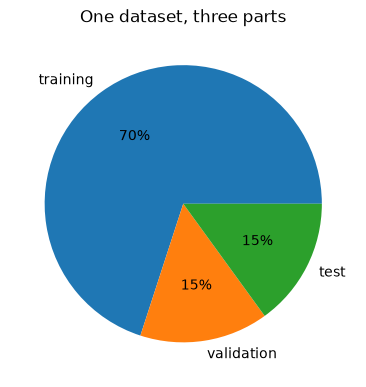

In [6]:
sizes = [len(split["train_idx"]), len(split["val_idx"]), len(split["test_idx"])]
plt.figure(figsize=(4.5, 4.5))   # square, so the pie is round
# pie(sizes) works out the shares itself. autopct writes the % in each slice:
# "%1.0f%%" means a number with 0 decimals, then a % sign (%% is how you write one % in this format)
plt.pie(sizes, labels=["training", "validation", "test"], autopct="%1.0f%%")
plt.title("One dataset, three parts")
plt.show()

**Bar chart, comparing categories:** how many wafers have each defect. The short bars are the defects the model gets the fewest examples of.

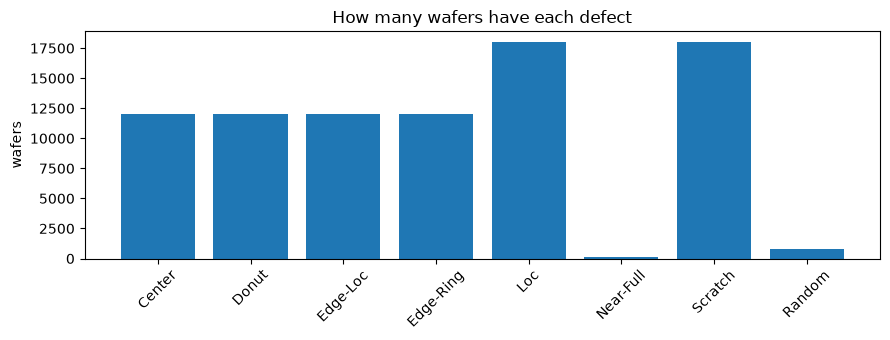

In [7]:
per_defect = []
for i in range(8):
    # labels[:, i] is column i for every wafer: is defect i there (1) or not (0). Count the 1s.
    per_defect.append((labels[:, i] == 1).sum())
plt.figure(figsize=(9, 3.5))
plt.bar(wafer.DEFECTS, per_defect)
plt.xticks(rotation=45)   # tilt the names so they don't overlap
plt.ylabel("wafers")
plt.title("How many wafers have each defect")
plt.tight_layout()
plt.show()

**Line graph, a trend:** my data has no time in it, so the trend I show is the score as the forest gets more trees (from notebook 05). A flat line means more trees only cost time.

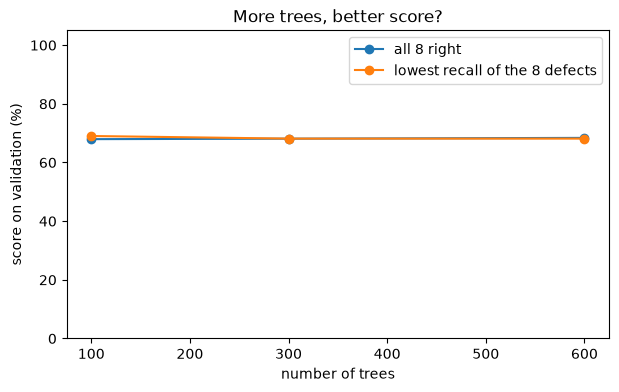

In [8]:
trees = []       # x: the number of trees
all_right = []   # y line 1: share of validation wafers with all 8 answers right
lowest = []      # y line 2: the recall of the weakest defect
for row in read_csv("output/settings_tried.csv"):   # the settings 05 tried, one row each
    if row["setting"].endswith("trees"):      # only the rows where nothing else changed
        # csv gives text, so int()/float() turn it back into numbers; * 100 makes a share a percentage
        trees.append(int(row["trees"]))
        all_right.append(float(row["all_eight_right_val"]) * 100)
        lowest.append(float(row["lowest_recall_val"]) * 100)

plt.figure(figsize=(7, 4))
# plot(x, y) draws a line through the points; marker="o" also puts a dot on every point
plt.plot(trees, all_right, marker="o", label="all 8 right")
plt.plot(trees, lowest, marker="o", label="lowest recall of the 8 defects")
plt.xlabel("number of trees")
plt.ylabel("score on validation (%)")
plt.ylim(0, 105)   # from 0, so a small difference doesn't look big; 105 leaves room above 100
plt.legend()
plt.title("More trees, better score?")
plt.show()

**Scatter plot, how two variables relate:** this matters most for machine learning, because a relationship between two numbers is exactly what a model learns. Every dot is one training wafer: across is ring_0 (the middle), up is ring_4 (the edge).

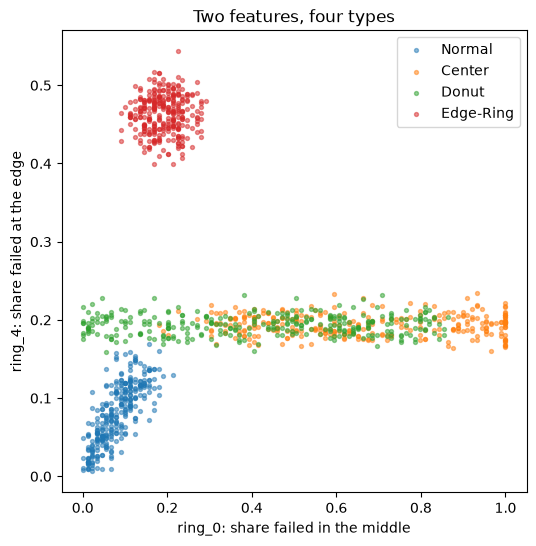

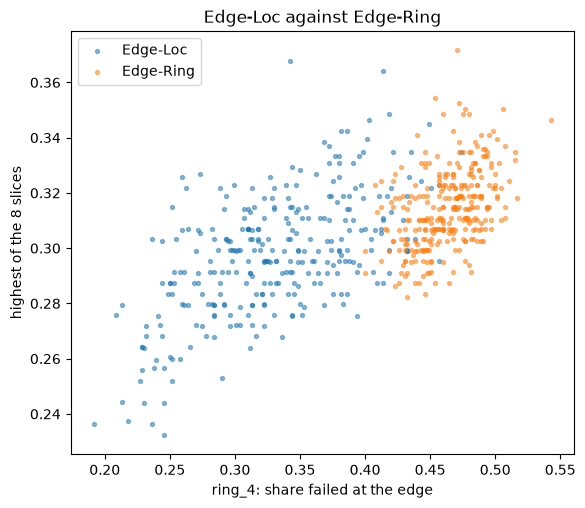

In [9]:
X_train = f["X_train"]   # the feature table: one row per training wafer, 14 columns
y_train = f["y_train"]   # the labels of those wafers

plt.figure(figsize=(6, 6))
# the first 300 Normal wafers (no defect). [:300] takes at most 300, so the dots don't become one blob
normal = np.where(y_train.sum(axis=1) == 0)[0][:300]
# scatter(x, y): one dot per wafer. Column 1 is ring_0, column 5 is ring_4 (see wafer.FEATURE_NAMES).
# s = dot size, alpha=0.5 = half see-through, so you can see where dots pile up
plt.scatter(X_train[normal, 1], X_train[normal, 5], s=8, alpha=0.5, label="Normal")
for name in ["Center", "Donut", "Edge-Ring"]:
    rows = wafers_with_only(name, y_train)[:300]     # at most 300 per type, so it stays readable
    plt.scatter(X_train[rows, 1], X_train[rows, 5], s=8, alpha=0.5, label=name)
plt.xlabel("ring_0: share failed in the middle")
plt.ylabel("ring_4: share failed at the edge")
plt.legend()
plt.title("Two features, four types")
plt.show()

plt.figure(figsize=(6.5, 5.5))
for name in ["Edge-Loc", "Edge-Ring"]:
    rows = wafers_with_only(name, y_train)[:300]
    # x: ring_4. y: columns 6 to 13 are the 8 slices; .max(axis=1) takes the highest slice per wafer.
    # Edge-Loc is a spot on one side, so one slice is high; Edge-Ring is all round, so no slice stands out.
    plt.scatter(X_train[rows, 5], X_train[rows, 6:14].max(axis=1), s=8, alpha=0.5, label=name)
plt.xlabel("ring_4: share failed at the edge")
plt.ylabel("highest of the 8 slices")
plt.legend()
plt.title("Edge-Loc against Edge-Ring")
plt.show()

**What it shows:** The pie is the three parts. The bars show which defects the model gets the fewest examples of.
The line shows whether more trees help or only cost time. In the scatters, look where colours overlap: there the
model can't tell two patterns apart on these two features. Compare that with the mix-ups in section 8.

## 6. Inside the forest: questions, trees and a vote

**In short:** A random forest is 300 decision trees. Each tree asks yes/no questions about the 14 numbers and ends in an answer for all 8 defects. Every tree is trained on a slightly different random part of the data, so they make different mistakes. Then they vote, and above half yes means yes.

**How to read it:** First the real questions the first tree asks, cut off after 3 levels. Each line is a question, indented under the question before it. Then the vote for one wafer: every bar is the share of trees that said "yes, it's there", the red line at 0.5 is where it becomes a yes. Last, how much the forest used each feature.

The forest has 300 trees. The top of the first one:

|--- share_failed <= 0.32
|   |--- slice_3 <= 0.14
|   |   |--- ring_3 <= 0.17
|   |   |   |--- ring_1 <= 0.27
|   |   |   |--- ring_1 >  0.27
|   |   |--- ring_3 >  0.17
|   |   |   |--- ring_3 <= 0.23
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- ring_3 >  0.23
|   |   |   |   |--- truncated branch of depth 5
|   |--- slice_3 >  0.14
|   |   |--- ring_4 <= 0.44
|   |   |   |--- ring_1 <= 0.26
|   |   |   |   |--- truncated branch of depth 17
|   |   |   |--- ring_1 >  0.26
|   |   |   |   |--- truncated branch of depth 17
|   |   |--- ring_4 >  0.44
|   |   |   |--- ring_0 <= 0.30
|   |   |   |   |--- truncated branch of depth 17
|   |   |   |--- ring_0 >  0.30
|   |   |   |   |--- truncated branch of depth 17
|--- share_failed >  0.32
|   |--- ring_4 <= 0.45
|   |   |--- ring_2 <= 0.31
|   |   |   |--- ring_2 <= 0.23
|   |   |   |   |--- truncated branch of depth 16
|   |   |   |--- ring_2 >  0.23
|   |   |   |

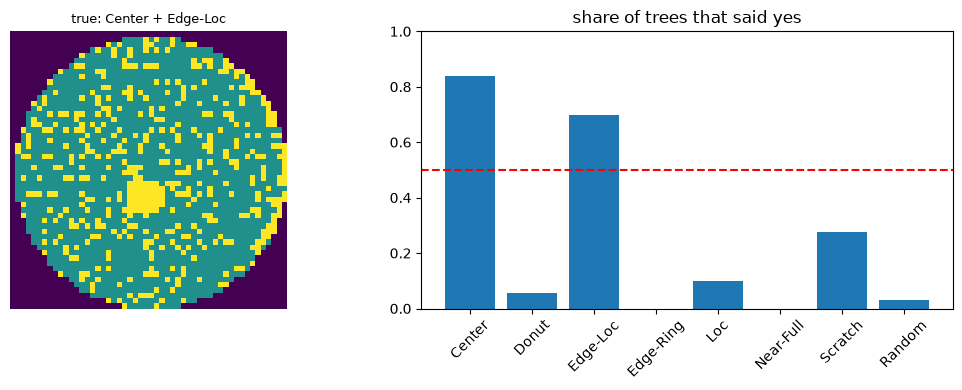

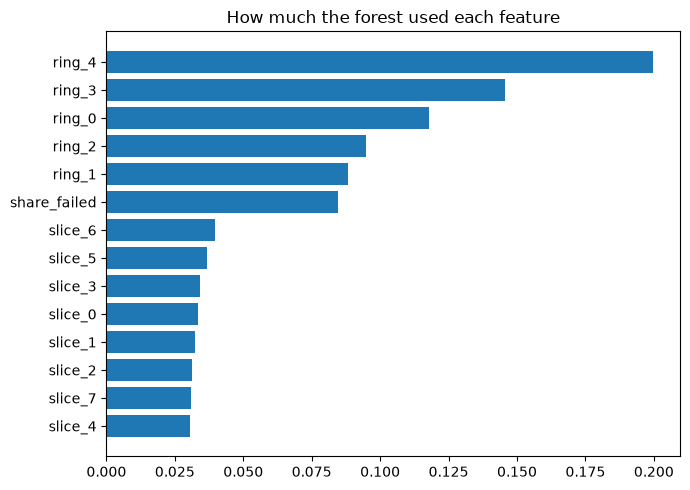

In [10]:
# estimators_ is the list of the forest's trees; [0] is the first one
first_tree = forest.estimators_[0]
print(f"The forest has {len(forest.estimators_)} trees. The top of the first one:")
print()
# export_text prints a tree as text. I leave out its "class" lines: with 8 answers they can't show all 8
#   feature_names: use my names (ring_0 ...) instead of feature_0, feature_1 ...
#   max_depth=3:   only the first 3 levels of questions, the full tree is far too long to read
text = export_text(first_tree, feature_names=wafer.FEATURE_NAMES, max_depth=3)
for line in text.split("\n"):
    if "class" not in line:
        print(line)


def votes(w):
    # predict_proba gives per defect [chance no, chance yes]. I keep the "yes" part
    # The model wants a table, even for one wafer: [features] makes it 1 row of 14 columns
    x = np.array([wafer.features(w)])
    # With 8 answers, chances is a list of 8 arrays, one per defect, each of shape (wafers, 2)
    chances = forest.predict_proba(x)
    yes = []
    for i in range(8):
        # chances[i] = defect i, [0] = the first (only) wafer, [1] = the "yes" column
        yes.append(chances[i][0][1])
    return yes


# the first test wafer with exactly 2 defects
i = np.where(test_labels.sum(axis=1) == 2)[0][0]
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.imshow(test_maps[i])
plt.title("true: " + wafer.label_name(test_labels[i]), fontsize=9)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.bar(wafer.DEFECTS, votes(test_maps[i]))
# axhline = a horizontal line across the whole plot at y = 0.5; "--" makes it dashed
plt.axhline(0.5, color="red", linestyle="--")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.title("share of trees that said yes")
plt.tight_layout()
plt.show()

# feature_importances_: 14 numbers that add up to 1. How much the questions on each feature helped
# split the wafers apart, over all trees. Higher = the forest leaned on it more.
importance = forest.feature_importances_
order = np.argsort(importance)   # least used first, so the most used ends up at the top of the chart
names = []
for k in order:
    names.append(wafer.FEATURE_NAMES[k])
plt.figure(figsize=(7, 5))
plt.barh(range(14), importance[order])   # barh = bars sideways, so the names are easy to read
plt.yticks(range(14), names)
plt.title("How much the forest used each feature")
plt.tight_layout()
plt.show()

**What it shows:** The first questions of one tree. Then the vote for one wafer: which bars are above the red line,
and are they the wafer's true defects? Last, which features the forest used most.

## 7. How well it works

**In short:** These are the scores on the test part, the final exam, opened once in notebook 06. Per defect, next to the simple model from notebook 04, the baseline the forest has to beat. Recall is how many of the real defects it found.

**How to read it:** The blue bars are my model, the orange ones the simple model, the dashed line my minimum of 70% (QC-01). Then the ranking, and the score per number of defects next to DC-Net, the model from the dataset's authors.

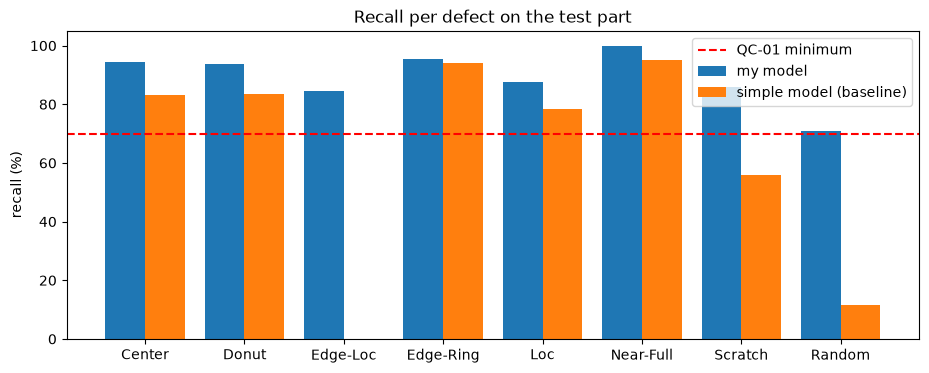

Most problematic first:
1. Random: recall 71.0%, precision 97.6%
2. Edge-Loc: recall 84.4%, precision 92.8%
3. Scratch: recall 86.0%, precision 76.9%
4. Loc: recall 87.5%, precision 95.4%
5. Donut: recall 93.8%, precision 96.4%
6. Center: recall 94.5%, precision 93.5%
7. Edge-Ring: recall 95.3%, precision 91.7%
8. Near-Full: recall 100.0%, precision 87.5%


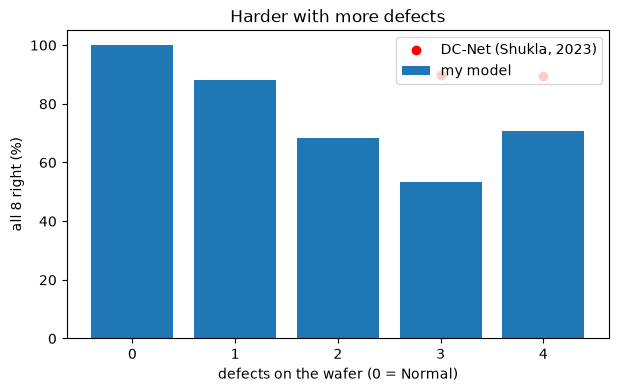

In [11]:
# recall = of the wafers that really have the defect, the share the model found
# precision = of the wafers the model said yes to, the share that really have it
recall, precision = wafer.scores_per_defect(y_test, y_pred)
base_recall, base_precision = wafer.scores_per_defect(y_test, y_base)
x = np.arange(8)   # 0, 1, ... 7: one place per defect

plt.figure(figsize=(11, 4))
# Two bars next to each other per defect: bar(x positions, heights, width). Each is 0.4 wide, one moved
# 0.2 to the left and one 0.2 to the right, so together they fill 0.8 around each defect's place.
plt.bar(x - 0.2, recall * 100, 0.4, label="my model")
plt.bar(x + 0.2, base_recall * 100, 0.4, label="simple model (baseline)")
plt.axhline(70, color="red", linestyle="--", label="QC-01 minimum")
plt.xticks(x, wafer.DEFECTS)   # put the names under the places 0 ... 7
plt.ylabel("recall (%)")
plt.ylim(0, 105)
plt.title("Recall per defect on the test part")
plt.legend()
plt.show()

print("Most problematic first:")
for row in read_csv("output/test_scores.csv"):   # 06 saved it already ranked
    # :.1f = 1 decimal. Two f-strings next to each other are glued into one.
    print(f"{row['rank']}. {row['defect']}: recall {float(row['recall']) * 100:.1f}%, "
          f"precision {float(row['precision']) * 100:.1f}%")

groups = []   # "0", "1", "2" ... defects on the wafer
scores = []   # all 8 right, in %
for row in read_csv("output/test_per_number_of_defects.csv"):
    if row["defects_on_wafer"] != "all":   # skip the total row, I only want the groups
        groups.append(row["defects_on_wafer"])
        scores.append(float(row["all_eight_right"]) * 100)
plt.figure(figsize=(7, 4))
plt.bar(groups, scores, label="my model")
# DC-Net's two published numbers, typed in from the paper. zorder=3 draws the dots on top of the bars.
plt.scatter(["3", "4"], [89.74, 89.61], color="red", zorder=3, label="DC-Net (Shukla, 2023)")
plt.xlabel("defects on the wafer (0 = Normal)")
plt.ylabel("all 8 right (%)")
plt.ylim(0, 105)
plt.legend()
plt.title("Harder with more defects")
plt.show()

**What it shows:** Recall per defect next to the simple model and the 70% line, the ranking, and all 8 right per number
of defects next to DC-Net. DC-Net's numbers come from a withdrawn preprint (Shukla, 2023) that split randomly with
the copies still in, so they are a reference point, not a fair race. DC-Net is a neural network on the whole
picture, mine only gets 14 numbers.

## 8. Where it goes wrong

**In short:** A score says how often it's wrong. These two say how. The first is what the model said instead when it missed a defect. The second is where on the wafer the missed ones had their failed chips.

**How to read it:** In the heatmap, a row is the defect it missed and a column what it said instead. Brighter is more. In the wafer pictures, a bright spot is where the missed wafers have their failure.

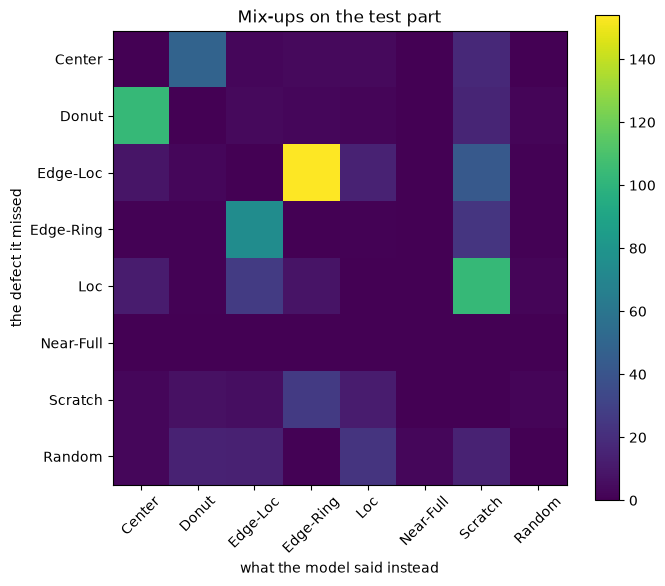

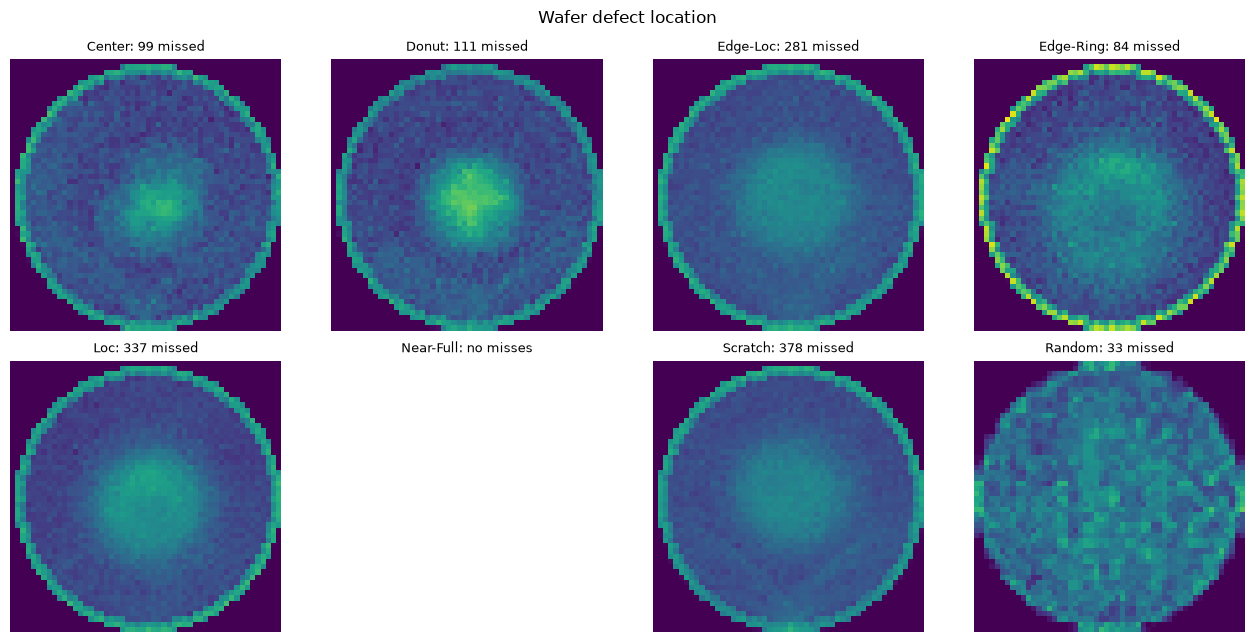

In [12]:
# test_mixups.csv: one row per missed defect, one column per defect it said instead.
# Turn it into a list of 8 lists of 8 numbers, a grid imshow can draw.
mixups = []
for row in read_csv("output/test_mixups.csv"):
    numbers = []
    for defect in wafer.DEFECTS:
        numbers.append(int(row[defect]))
    mixups.append(numbers)

plt.figure(figsize=(7, 6))
plt.imshow(mixups)   # an 8 x 8 grid as colours: a heatmap
plt.colorbar()       # the scale next to it: which colour is which number
plt.xticks(range(8), wafer.DEFECTS, rotation=45)
plt.yticks(range(8), wafer.DEFECTS)
plt.xlabel("what the model said instead")
plt.ylabel("the defect it missed")
plt.title("Mix-ups on the test part")
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 6.5))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    # True for the test wafers that have defect i (y_test 1) and where the model said no (y_pred 0).
    # & is "and" for whole arrays at once.
    missed = (y_test[:, i] == 1) & (y_pred[:, i] == 0)
    if missed.sum() == 0:
        plt.title(f"{wafer.DEFECTS[i]}: no misses", fontsize=9)
    else:
        # test_maps[missed]   only the missed wafers, shape (missed, 52, 52)
        # == 2                True where a chip failed
        # .mean(axis=0)       per square: on what share of the missed wafers it failed -> one 52 x 52 picture
        # vmin=0, vmax=1      the same colour scale on all 8, so a bright spot means the same everywhere
        plt.imshow((test_maps[missed] == 2).mean(axis=0), vmin=0, vmax=1)
        plt.title(f"{wafer.DEFECTS[i]}: {missed.sum()} missed", fontsize=9)
    plt.axis("off")
plt.suptitle("Wafer defect location")
plt.tight_layout()
plt.show()

**What it shows:** In the heatmap, the brightest squares are the mix-ups that happen most. In the wafer pictures,
the bright parts are where the missed wafers have their failure.

## 9. My own wafers

**In short:** I drew 1,900 wafers myself, by rules, for all 38 types, and tested the model on them without training on them. That shows whether it knows the patterns or only MixedWM38's version of them.

**How to read it:** Top row real wafers, bottom row mine. Then recall on the real test part next to recall on my wafers.

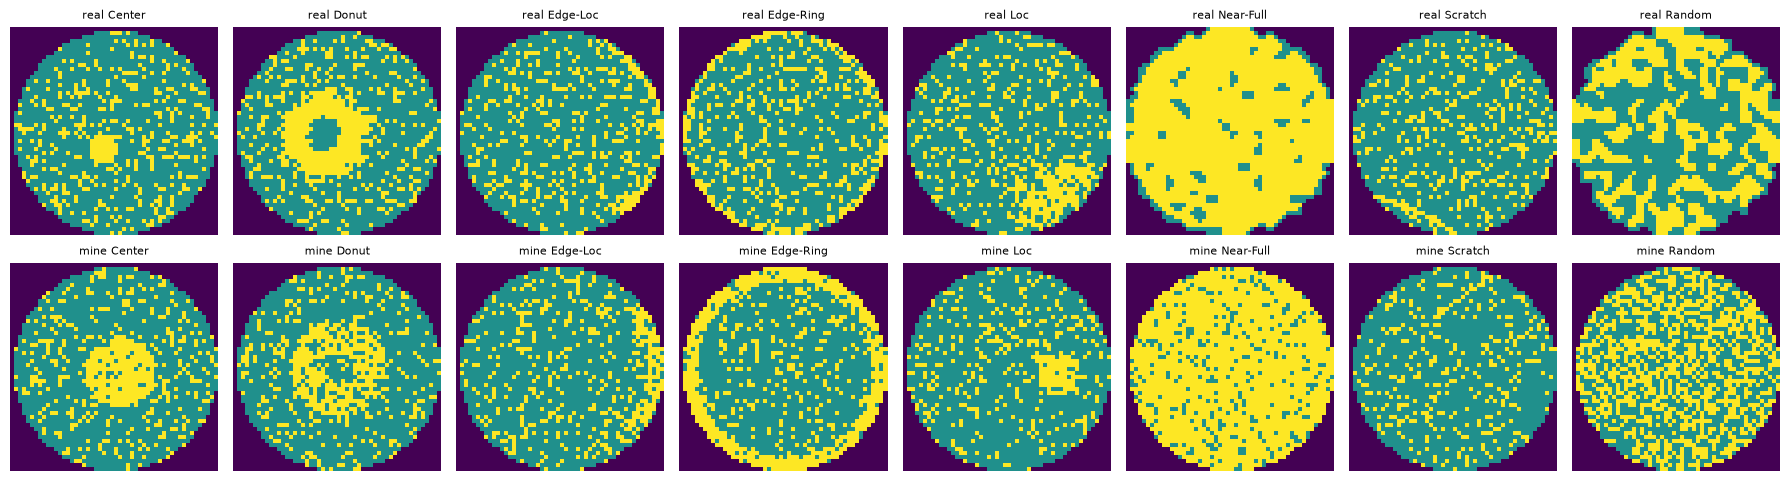

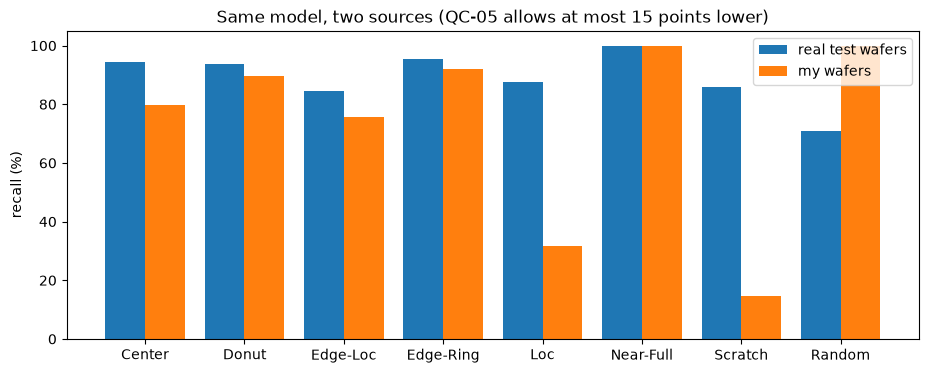

In [13]:
# 07 makes generated.npz. If it wasn't run, say so instead of crashing.
if not os.path.exists("output/generated.npz"):
    print("Notebook 07 wasn't run, so there's nothing to show here")
else:
    gen = np.load("output/generated.npz")   # my own drawn wafers: gen["maps"] and gen["labels"]
    plt.figure(figsize=(18, 5))
    for i in range(8):
        defect = wafer.DEFECTS[i]
        # a grid of 2 rows and 8 columns: top row places 1-8 are real, bottom row places 9-16 mine
        plt.subplot(2, 8, i + 1)
        plt.imshow(maps[wafers_with_only(defect, labels)[0]])
        plt.title(f"real {defect}", fontsize=8)
        plt.axis("off")
        plt.subplot(2, 8, i + 9)
        plt.imshow(gen["maps"][wafers_with_only(defect, gen["labels"])[0]])
        plt.title(f"mine {defect}", fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

    real_r = []   # recall per defect on the real test wafers
    mine_r = []   # recall per defect on my wafers
    for row in read_csv("output/generated_scores.csv"):
        real_r.append(float(row["recall_real_test"]) * 100)
        mine_r.append(float(row["recall_my_wafers"]) * 100)
    x = np.arange(8)
    plt.figure(figsize=(11, 4))
    # two bars per defect again: 0.4 wide, 0.2 left and 0.2 right of the defect's place
    plt.bar(x - 0.2, real_r, 0.4, label="real test wafers")
    plt.bar(x + 0.2, mine_r, 0.4, label="my wafers")
    plt.xticks(x, wafer.DEFECTS)
    plt.ylabel("recall (%)")
    plt.ylim(0, 105)
    plt.title("Same model, two sources (QC-05 allows at most 15 points lower)")
    plt.legend()
    plt.show()

**What it shows:** Per defect, recall on the real test part next to my wafers. Where the two bars differ by more
than 15 points, QC-05 fails for that defect.

## 10. Did it do what I promised?

**In short:** Every test I wrote down before running anything, carried out by notebook 08.

**How to read it:** One line per test, with Pass, Fail, Not run or Check by eye.

In [14]:
# validation.csv is the table 08 made: one row per test
for row in read_csv("output/validation.csv"):
    print(f"{row['No']}: {row['Pass/Fail']}  ({row['What']})")

T1: Pass  (FR-01 8 position label for every wafer)
T2: Pass  (FR-02 label becomes a name, or Normal)
T3: Pass  (FR-03 copies removed before the split)
T4: Pass  (FR-04 value 3 handled one way)
T5: Pass  (FR-05 every type in every part)
T6: Pass  (FR-06 baseline next to the model)
T7: Pass  (FR-07 per defect and per number of defects)
T8: Pass  (FR-08 the 8 types ranked)
T9: Pass  (FR-09 generator for the 38 types)
T10: Check by eye  (FR-10 where the misses sit)
V1: Pass  (no map in two parts)
V2: Pass  (every type in every part)
V3: Pass  (no value 3 left)
V4: Pass  (same seed, same split and scores)
QC-01: Pass  (recall per type, min 70%)
QC-02: Pass  (all 8 right, min 60%)
QC-03: Pass  (precision, min 60%)
QC-04: Fail  (beats the simple model on every type)
QC-05: Fail  (own wafers at most 15 points lower)
QC-06: Pass  (same seed, same split and scores)
QC-07: Pass  (training under 60 min)
QC-08: Pass  (one wafer under 50 ms)
QC-09: Pass  (1000 wafers under 10 s)


**What it shows:** Every test with its verdict. The fails stay in.

## 11. The live demo

**In short:** pick any test wafer, and the model says what's wrong with it.

**How to read it:** left is the wafer. In the middle are the 14 numbers the model gets, next to an average Normal
wafer. On the right is the vote of the 300 trees, with the yes line at 0.5. Under it: what the model says, how long
it took with the features included (QC-08), and the true label.

`show(number)` does all of that for one wafer. Change `WAFER` and run the cell.

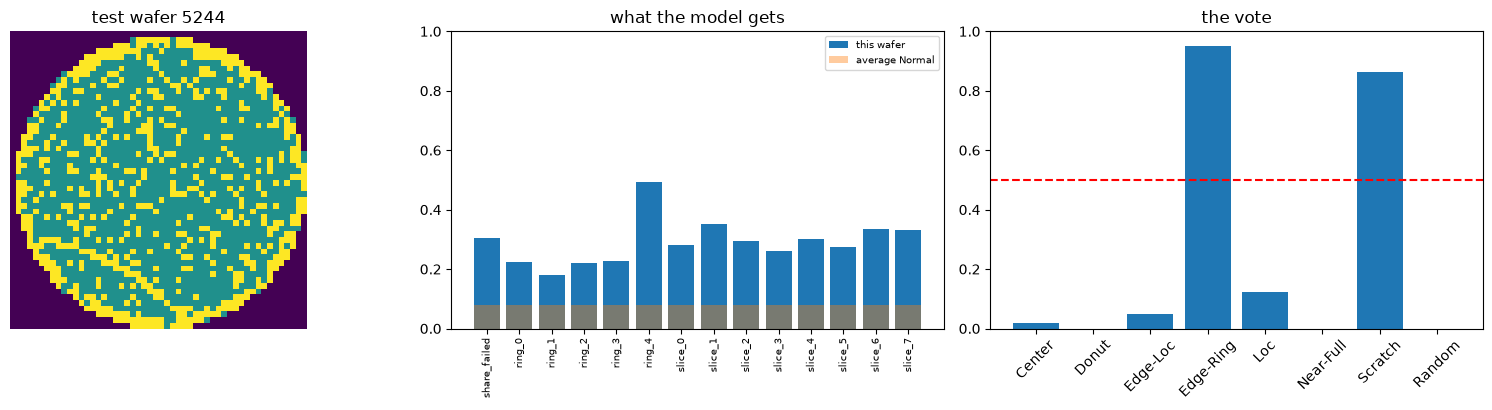

The model says: Edge-Ring + Scratch (in 15 ms)
The true label: Edge-Ring + Scratch
Correct


In [15]:
def show(number):
    # number = the position of a wafer in the test part
    w = test_maps[number]
    true = test_labels[number]

    # From map to answer, timed, features included
    # perf_counter is a precise clock in seconds; the difference before and after is how long it took
    start = time.perf_counter()
    x = np.array([wafer.features(w)])   # 1 row of 14 numbers, because the model wants a table
    said = forest.predict(x)[0]         # predict gives one row of 8 zeros/ones per wafer; [0] = this wafer
    ms = (time.perf_counter() - start) * 1000   # seconds -> milliseconds

    plt.figure(figsize=(16, 4.2))
    # left: the wafer
    plt.subplot(1, 3, 1)
    plt.imshow(w)
    plt.title(f"test wafer {number}")
    plt.axis("off")

    # middle: its 14 numbers over the average Normal (normal_average comes from section 4)
    plt.subplot(1, 3, 2)
    plt.bar(range(14), x[0], label="this wafer")
    plt.bar(range(14), normal_average, alpha=0.4, label="average Normal")
    plt.xticks(range(14), wafer.FEATURE_NAMES, rotation=90, fontsize=7)
    plt.ylim(0, 1)
    plt.legend(fontsize=7)
    plt.title("what the model gets")

    # right: the share of the 300 trees that said yes per defect (votes() comes from section 6)
    plt.subplot(1, 3, 3)
    plt.bar(wafer.DEFECTS, votes(w))
    plt.axhline(0.5, color="red", linestyle="--")   # above this line the answer is yes
    plt.xticks(rotation=45)
    plt.ylim(0, 1)
    plt.title("the vote")
    plt.tight_layout()
    plt.show()

    print("The model says:", wafer.label_name(said), f"(in {ms:.0f} ms)")
    print("The true label:", wafer.label_name(true))
    # said == true compares the 8 positions; .all() is True only if all 8 match
    if (said == true).all():
        print("Correct")
    else:
        print("WRONG")


WAFER = 5244     # <- any test wafer, from 0 to len(test_maps) - 1
show(WAFER)

### Three runs

Found automatically: a wafer with one defect, one with three or more, and the first one the model gets wrong that
isn't one of those two. For the wrong one, look at the middle picture: which of its numbers look like
another pattern?

In [16]:
how_many = test_labels.sum(axis=1)                 # number of defects per test wafer
one_defect = np.where(how_many == 1)[0][0]          # the first with exactly 1
many_defects = np.where(how_many >= 3)[0][0]        # the first with 3 or more
# (y_pred == y_test).all(axis=1) is True where all 8 answers are right; ~ flips it to "not all right".
# np.where gives the positions of those wrong wafers.
wrong = np.where(~(y_pred == y_test).all(axis=1))[0]
# Skip the two wafers above, so these are three different wafers
# (keep only the positions that are not one_defect and not many_defects)
wrong = wrong[(wrong != one_defect) & (wrong != many_defects)]

print("One defect: test wafer", one_defect)
print("Three or more: test wafer", many_defects)
print("One it gets wrong: test wafer", wrong[0])

One defect: test wafer 1650
Three or more: test wafer 0
One it gets wrong: test wafer 2


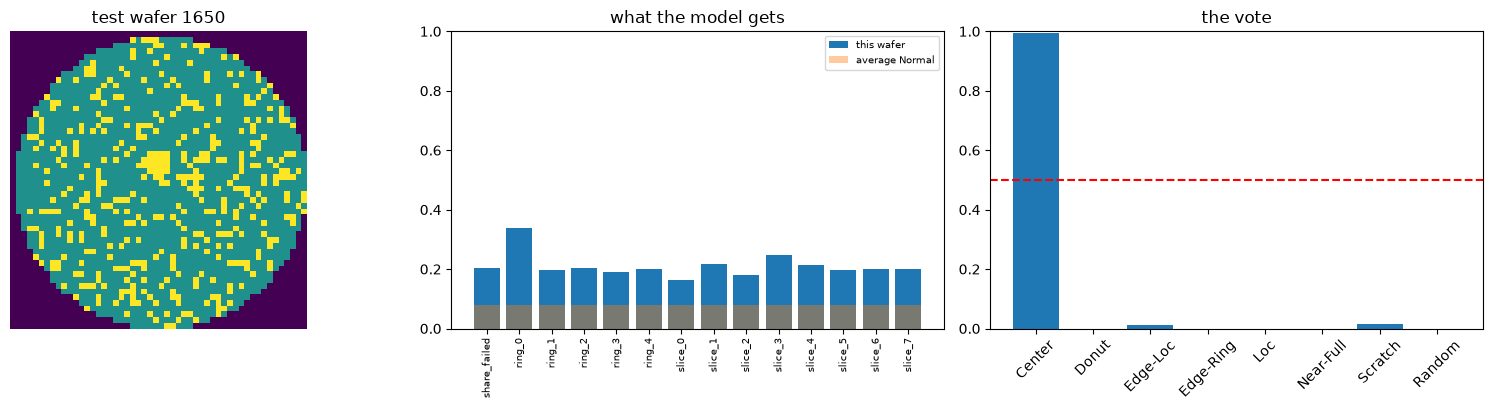

The model says: Center (in 16 ms)
The true label: Center
Correct


In [17]:
show(one_defect)

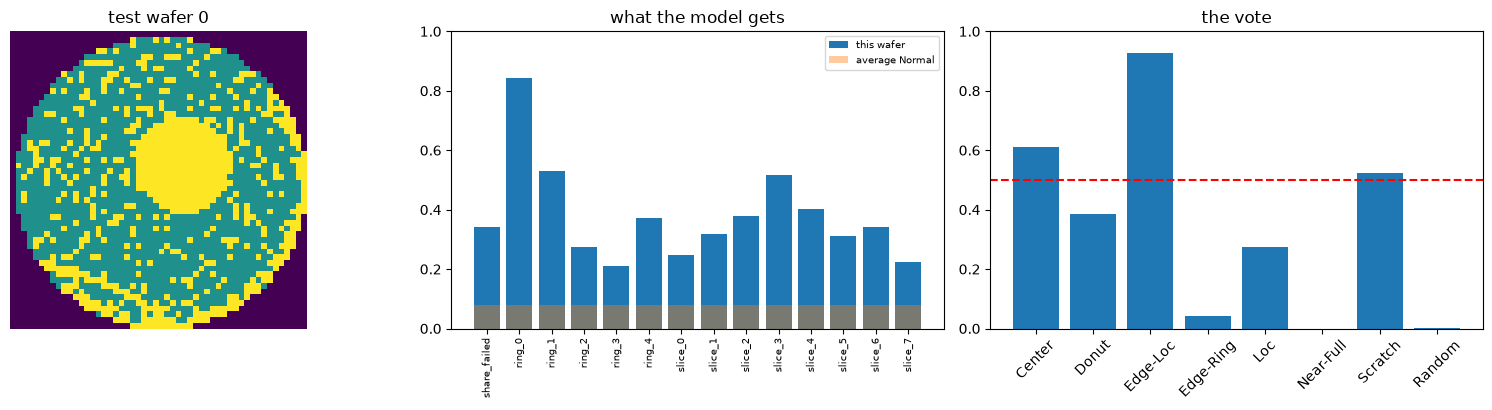

The model says: Center + Edge-Loc + Scratch (in 14 ms)
The true label: Center + Edge-Loc + Scratch
Correct


In [18]:
show(many_defects)

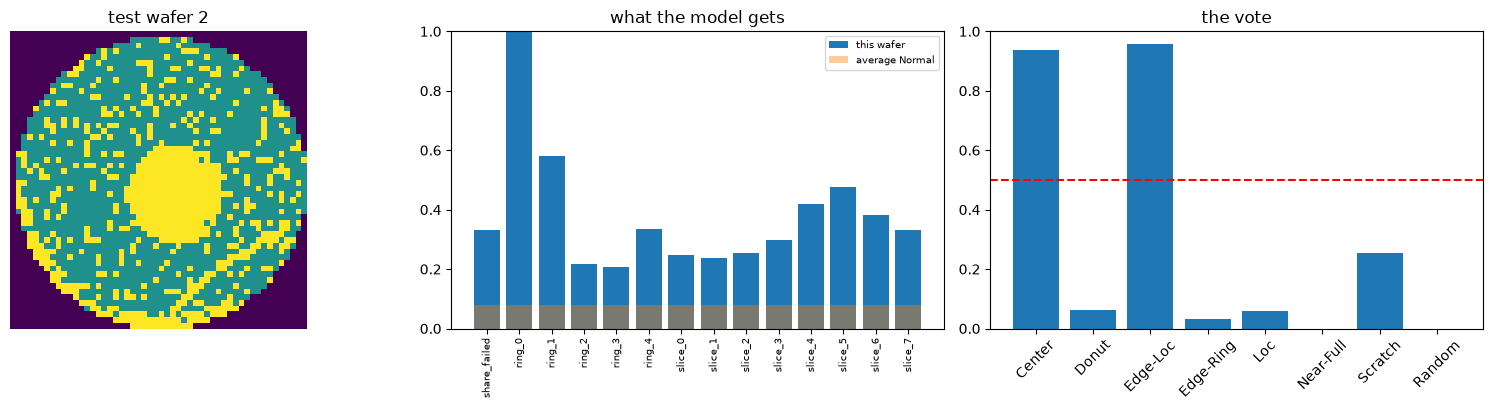

The model says: Center + Edge-Loc (in 15 ms)
The true label: Center + Edge-Loc + Scratch
WRONG


In [19]:
show(wrong[0])

## Functions in this notebook

| Function | What it does | Where to read more |
|---|---|---|
| `plt.bar / plt.barh` | bars up / bars sideways | [docs](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html) |
| `plt.pie` | a pie chart | [docs](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.pie.html) |
| `plt.plot` | a line through points | [docs](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html) |
| `plt.scatter` | one dot per pair of numbers | [docs](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) |
| `plt.contour` | lines where a grid changes value, here the rings | [docs](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.contour.html) |
| `plt.colorbar` | the colour scale next to a heatmap | [docs](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html) |
| `export_text` | prints a decision tree as text | [docs](https://scikit-learn.org/stable/modules/generated/sklearn.tree.export_text.html) |
| `.predict_proba` | per defect, the share of trees that said yes | [docs](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) |